In [1]:
# Experiment 02 — Hadamard Circuit Visualization and Probability Estimation

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import numpy as np

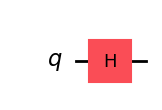

In [3]:
# Create a single-qubit circuit
qc = QuantumCircuit(1)

# Apply the Hadamard gate
qc.h(0)

# Display the quantum circuit
display(qc.draw("mpl"))

Statevector: [0.70710678+0.j 0.70710678+0.j]
Probability of |0>: 0.4999999999999999
Probability of |1>: 0.4999999999999999


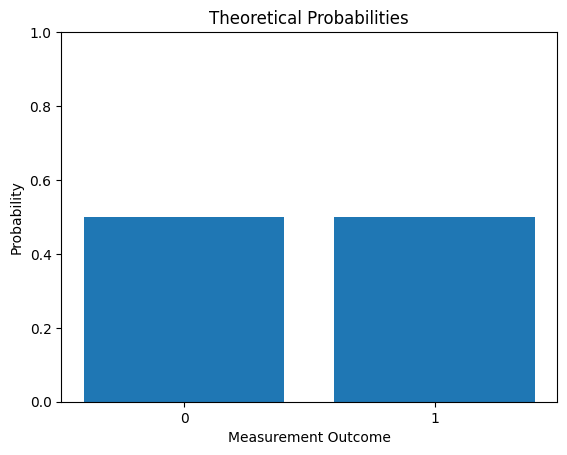

In [4]:
# Get the statevector after applying Hadamard
state = Statevector.from_instruction(qc)

# Calculate measurement probabilities
probabilities = state.probabilities()

print("Statevector:", state.data)
print("Probability of |0>:", probabilities[0])
print("Probability of |1>:", probabilities[1])

# Plot theoretical probabilities
plt.bar(["0", "1"], probabilities)
plt.xlabel("Measurement Outcome")
plt.ylabel("Probability")
plt.title("Theoretical Probabilities")
plt.ylim(0, 1)
plt.show()

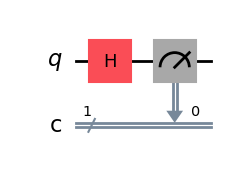

Measurement Counts: {'1': 498, '0': 526}


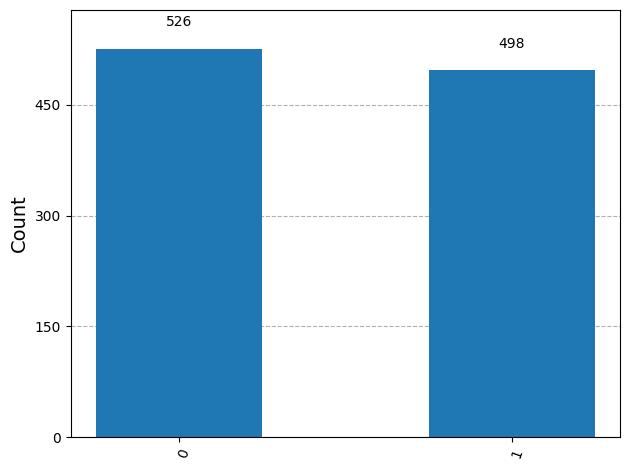

In [5]:
# Create a circuit with measurement
qc_measure = QuantumCircuit(1, 1)

qc_measure.h(0)
qc_measure.measure(0, 0)

# Display the circuit
display(qc_measure.draw("mpl"))

# Run 1024 measurements
simulator = AerSimulator()

result = simulator.run(
    transpile(qc_measure, simulator),
    shots=1024,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Measurement Counts:", counts)

# Display the measurement histogram
display(plot_histogram(counts))

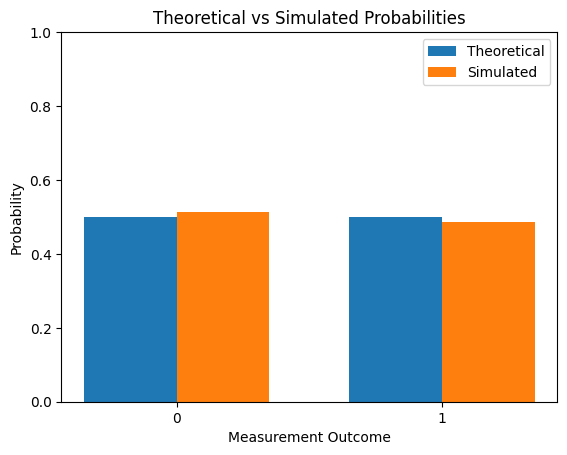

Theoretical: [0.5 0.5]
Simulated: [0.5137 0.4863]


In [6]:
# Calculate simulated probabilities
shots = sum(counts.values())

simulated = [
    counts.get("0", 0) / shots,
    counts.get("1", 0) / shots
]

# Compare both probability distributions
x = np.arange(2)
width = 0.35

plt.bar(x - width/2, probabilities, width, label="Theoretical")
plt.bar(x + width/2, simulated, width, label="Simulated")

plt.xticks(x, ["0", "1"])
plt.xlabel("Measurement Outcome")
plt.ylabel("Probability")
plt.title("Theoretical vs Simulated Probabilities")
plt.ylim(0, 1)
plt.legend()
plt.show()

print("Theoretical:", np.round(probabilities, 4))
print("Simulated:", np.round(simulated, 4))